# Experimento: tamanho da reserva nos corredores de migração

Mesma proteção do `Experiment_migration_protection.ipynb` (mecanismo `reserva`, σ(e) divulgado pelo mediador), variando a fração de slots reservados nos enlaces protegidos: **10%, 25% e 40%**. Cada porcentagem roda em par:

| Par | O que faz |
|---|---|
| `reserva` | enlaces do corredor exclusivos do conjunto cooperante $K$ |
| `reserva_isolado` (proteção individual) | cada ISP que reagiu protege os enlaces que só ele usa, cooperando ou não |

Os 32 conjuntos $K$ para cada um → 6 × 32 = 192 rodadas. As de 25% já existem (`prot-reserva` e `prot-reserva_isolado`) e são reaproveitadas, então faltam 128.

**Pergunta:** qual porcentagem dá o melhor ganho de migração pelo custo no tráfego de fundo, e a vantagem da cooperação sobre o controle se mantém em todas?

Referência (`pesos`): `output/cooperation_experiment_v2`, sem proteção. Modulação por distância, roteador v2.

In [10]:
import os
from concurrent.futures import ProcessPoolExecutor, as_completed
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from experiment_worker import run_cooperation_experiment
from run_cooperation_experiment import (
    PROTECOES,
    consolidar,
    montar_tarefas,
    nome_reserva,
    pasta_saida,
)

%matplotlib inline

## Parâmetros

In [ ]:
BASE_INDICES = [0]
PORCENTAGENS = [10, 25, 40, 55, 70, 85]
MAX_WORKERS = min(os.cpu_count() or 4, 8)
# The original reference run (output/cooperation_experiment_v2) predates the
# per-group background metrics (B_n_K, B_n_isolados). True re-runs it (32 runs,
# no reservation) into its own folder so those panels get a reference line.
REFAZER_REFERENCIA = True
REFERENCIA = Path("output/cooperation_experiment_v2_ref") if REFAZER_REFERENCIA else pasta_saida(None)

VARIANTES = []   # (pct, escopo, nome em PROTECOES)
for pct in PORCENTAGENS:
    VARIANTES.append((pct, "cooperacao", nome_reserva(pct)))
    VARIANTES.append((pct, "isolado", nome_reserva(pct, isolado=True)))

tarefas = []
for pct, escopo, nome in VARIANTES:
    pasta = pasta_saida(None, nome)
    pasta.mkdir(parents=True, exist_ok=True)
    for t in montar_tarefas(BASE_INDICES, pasta, first_fit=False):
        t.update(output_dir=str(pasta), protecao=PROTECOES[nome], nome_variante=nome)
        tarefas.append(t)
if REFAZER_REFERENCIA:
    REFERENCIA.mkdir(parents=True, exist_ok=True)
    for t in montar_tarefas(BASE_INDICES, REFERENCIA, first_fit=False):
        t.update(output_dir=str(REFERENCIA), protecao=None, nome_variante="sem_reserva")
        tarefas.append(t)
for idx, t in enumerate(tarefas):
    t.update(run_index=idx, total_runs=len(tarefas))

print(f"{len(tarefas)} rodadas pendentes | {MAX_WORKERS} processos")
for pct, escopo, nome in VARIANTES:
    print(f"  {pct:>2}% {escopo:<10} → {pasta_saida(None, nome)}")
if not (REFERENCIA / "resumo_por_rodada.csv").exists():
    print(f"⚠️ Referência {REFERENCIA} não encontrada")

0 rodadas pendentes | 8 processos
  10% cooperacao → output/cooperation_experiment_v2_prot-reserva_10
  10% isolado    → output/cooperation_experiment_v2_prot-reserva_isolado_10
  25% cooperacao → output/cooperation_experiment_v2_prot-reserva
  25% isolado    → output/cooperation_experiment_v2_prot-reserva_isolado
  40% cooperacao → output/cooperation_experiment_v2_prot-reserva_40
  40% isolado    → output/cooperation_experiment_v2_prot-reserva_isolado_40
  55% cooperacao → output/cooperation_experiment_v2_prot-reserva_55
  55% isolado    → output/cooperation_experiment_v2_prot-reserva_isolado_55
  70% cooperacao → output/cooperation_experiment_v2_prot-reserva_70
  70% isolado    → output/cooperation_experiment_v2_prot-reserva_isolado_70
  85% cooperacao → output/cooperation_experiment_v2_prot-reserva_85
  85% isolado    → output/cooperation_experiment_v2_prot-reserva_isolado_85


## Rodar

Rodadas prontas são puladas; dá para interromper e continuar.

In [12]:
inicio = datetime.now()
falhas = []
if tarefas:
    with ProcessPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {executor.submit(run_cooperation_experiment, t): t for t in tarefas}
        for n, future in enumerate(as_completed(futures), start=1):
            r = future.result()
            estado = "✓" if r["success"] else "✗"
            print(f"[{n}/{len(tarefas)}] {estado} {futures[future]['nome_variante']} {r['K']}  ({datetime.now() - inicio})")
            if not r["success"]:
                falhas.append(r)
print(f"Duração: {datetime.now() - inicio} | falhas: {len(falhas)}")
for _, _, nome in VARIANTES:
    consolidar(pasta_saida(None, nome))
if REFAZER_REFERENCIA:
    consolidar(REFERENCIA)

Duração: 0:00:00.000175 | falhas: 0
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_10
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_isolado_10
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_isolado
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_40
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_isolado_40
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_55
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_isolado_55
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_70
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_isolado_70
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_85
✓ 32 runs consolidated in output/cooperation_experiment_v2_prot-reserva_isolado_85


## Carregar

In [13]:
def carregar(pasta, **rotulos):
    r = pd.read_csv(pasta / "resumo_por_rodada.csv")
    p = pd.read_csv(pasta / "resumo_por_isp.csv")
    filtro = lambda df: df[(df["variante"] == "cooperacao") & df["base_index"].isin(BASE_INDICES)]
    return filtro(r).assign(**rotulos), filtro(p).assign(**rotulos)

partes = [carregar(REFERENCIA, pct=0, escopo="pesos")]
partes += [carregar(pasta_saida(None, nome), pct=pct, escopo=escopo) for pct, escopo, nome in VARIANTES]
resumo = pd.concat([r for r, _ in partes], ignore_index=True)
por_isp = pd.concat([p for _, p in partes], ignore_index=True)
I = por_isp["isp_id"].nunique()
ref = resumo[resumo["escopo"] == "pesos"].set_index(["base_index", "K"])
resumo.groupby(["pct", "escopo"]).size()

pct  escopo    
0    pesos         32
10   cooperacao    32
     isolado       32
25   cooperacao    32
     isolado       32
40   cooperacao    32
     isolado       32
55   cooperacao    32
     isolado       32
70   cooperacao    32
     isolado       32
85   cooperacao    32
     isolado       32
dtype: int64

## Ganho de migração vs custo no tráfego de fundo

Média sobre os 32 conjuntos, e o caso com todos cooperando. Diferenças em relação a `pesos` (mesmo $K$).

In [14]:
linhas = []
for (pct, escopo), g in resumo[resumo["escopo"] != "pesos"].groupby(["pct", "escopo"]):
    g = g.set_index(["base_index", "K"])
    d_eta = g["eta_todos"] - ref["eta_todos"]
    d_bn = g["B_n"] - ref["B_n"]
    todos = g[g["k"] == I]
    linhas.append({
        "pct": pct, "escopo": escopo,
        "d_eta médio": d_eta.mean(), "d_B_n médio": d_bn.mean(),
        "K que melhoram": int((d_eta > 1e-9).sum()), "K que pioram": int((d_eta < -1e-9).sum()),
        "eta K=I": todos["eta_todos"].mean(), "B_n K=I": todos["B_n"].mean(),
        "d_eta K=I": (todos["eta_todos"] - ref["eta_todos"].reindex(todos.index)).mean(),
        "d_B_n K=I": (todos["B_n"] - ref["B_n"].reindex(todos.index)).mean(),
    })
tradeoff = pd.DataFrame(linhas).set_index(["pct", "escopo"])
tradeoff["ganho por ponto de B_n"] = tradeoff["d_eta médio"] / tradeoff["d_B_n médio"]
tradeoff.round(4)

d_eta médio  d_B_n médio  K que melhoram  K que pioram  \
pct escopo                                                               
10  cooperacao       0.0032       0.0011              18            11   
    isolado          0.0025       0.0007              26             6   
25  cooperacao       0.0106       0.0027              21             7   
    isolado          0.0113       0.0019              32             0   
40  cooperacao       0.0209       0.0050              24             5   
    isolado          0.0211       0.0036              32             0   
55  cooperacao       0.0290       0.0078              27             2   
    isolado          0.0297       0.0056              32             0   
70  cooperacao       0.0386       0.0119              28             1   
    isolado          0.0381       0.0081              32             0   
85  cooperacao       0.0456       0.0180              28             1   
    isolado          0.0507       0.0126              32             0   

                eta K=I  B_n K=I  d_eta K=I  d_B_n K=I  ganho por ponto de B_n  
pct escopo                                                                      
10  cooperacao   0.7981   0.2919     0.0149     0.0042                  3.0132  
    isolado      0.7928   0.2880     0.0096     0.0003                  3.6169  
25  cooperacao   0.8288   0.2975     0.0456     0.0098                  3.9036  
    isolado      0.8034   0.2895     0.0202     0.0018                  6.0680  
40  cooperacao   0.8598   0.3059     0.0766     0.0182                  4.2248  
    isolado      0.8050   0.2904     0.0218     0.0027                  5.7768  
55  cooperacao   0.8928   0.3168     0.1096     0.0292                  3.7033  
    isolado      0.8154   0.2918     0.0322     0.0041                  5.3165  
70  cooperacao   0.9247   0.3320     0.1415     0.0443                  3.2489  
    isolado      0.8268   0.2940     0.0436     0.0063                  4.6806  
85  cooperacao   0.9555   0.3546     0.1724     0.0669                  2.5359  
    isolado      0.8324   0.2970     0.0492     0.0093                  4.0278

## Por tamanho de $K$

In [15]:
for col in ["eta_todos", "B_n", "B_m"]:
    t = resumo.groupby(["pct", "escopo", "k"])[col].mean().unstack("k").round(4)
    print(f"\n{col}")
    display(t)


eta_todos


k                    0       1       2       3       4       5
pct escopo                                                    
0   pesos       0.7876  0.7876  0.7872  0.7872  0.7869  0.7832
10  cooperacao  0.7876  0.7865  0.7876  0.7895  0.8002  0.7981
    isolado     0.7882  0.7882  0.7887  0.7898  0.7927  0.7928
25  cooperacao  0.7876  0.7875  0.7922  0.8000  0.8106  0.8288
    isolado     0.7972  0.7972  0.7983  0.7982  0.7998  0.8034
40  cooperacao  0.7876  0.7903  0.7980  0.8129  0.8302  0.8598
    isolado     0.8091  0.8091  0.8091  0.8082  0.8058  0.8050
55  cooperacao  0.7876  0.7912  0.8019  0.8214  0.8491  0.8928
    isolado     0.8216  0.8216  0.8181  0.8149  0.8123  0.8154
70  cooperacao  0.7876  0.7959  0.8081  0.8319  0.8662  0.9247
    isolado     0.8247  0.8247  0.8255  0.8259  0.8239  0.8268
85  cooperacao  0.7876  0.7954  0.8132  0.8396  0.8798  0.9555
    isolado     0.8391  0.8391  0.8384  0.8372  0.8373  0.8324


B_n


k                    0       1       2       3       4       5
pct escopo                                                    
0   pesos       0.2876  0.2876  0.2876  0.2877  0.2876  0.2877
10  cooperacao  0.2876  0.2878  0.2882  0.2887  0.2901  0.2919
    isolado     0.2884  0.2884  0.2884  0.2883  0.2883  0.2880
25  cooperacao  0.2876  0.2882  0.2890  0.2907  0.2937  0.2975
    isolado     0.2895  0.2895  0.2895  0.2896  0.2895  0.2895
40  cooperacao  0.2876  0.2884  0.2901  0.2934  0.2986  0.3059
    isolado     0.2916  0.2916  0.2914  0.2912  0.2909  0.2904
55  cooperacao  0.2876  0.2888  0.2915  0.2968  0.3046  0.3168
    isolado     0.2936  0.2936  0.2934  0.2931  0.2928  0.2918
70  cooperacao  0.2876  0.2895  0.2936  0.3014  0.3135  0.3320
    isolado     0.2960  0.2960  0.2961  0.2957  0.2954  0.2940
85  cooperacao  0.2876  0.2903  0.2968  0.3085  0.3267  0.3546
    isolado     0.3008  0.3008  0.3005  0.3002  0.2996  0.2970


B_m


k                    0       1       2       3       4       5
pct escopo                                                    
0   pesos       0.5598  0.5598  0.5595  0.5593  0.5598  0.5609
10  cooperacao  0.5598  0.5596  0.5590  0.5575  0.5527  0.5505
    isolado     0.5597  0.5597  0.5595  0.5590  0.5587  0.5579
25  cooperacao  0.5598  0.5586  0.5561  0.5519  0.5453  0.5337
    isolado     0.5538  0.5538  0.5544  0.5547  0.5548  0.5552
40  cooperacao  0.5598  0.5592  0.5553  0.5474  0.5366  0.5209
    isolado     0.5527  0.5527  0.5523  0.5523  0.5530  0.5533
55  cooperacao  0.5598  0.5577  0.5525  0.5415  0.5264  0.4995
    isolado     0.5483  0.5483  0.5487  0.5495  0.5511  0.5501
70  cooperacao  0.5598  0.5571  0.5496  0.5347  0.5134  0.4813
    isolado     0.5449  0.5449  0.5450  0.5452  0.5453  0.5442
85  cooperacao  0.5598  0.5569  0.5466  0.5286  0.5002  0.4556
    isolado     0.5413  0.5413  0.5415  0.5411  0.5413  0.5418

## Ganho sobre o First-Fit disaster-aware

Cada estratégia comparada com a referência sem reserva (`pesos`, First-Fit disaster-aware ponderado), mesmo $K$: pontos de η total. Proteção cooperativa e individual são avaliadas separadamente contra essa referência.

In [16]:
difs = []
for (pct, escopo), g in resumo[resumo["escopo"] != "pesos"].groupby(["pct", "escopo"]):
    g = g.set_index(["base_index", "K"])
    d = (g["eta_todos"] - ref["eta_todos"]).rename("d").to_frame().assign(k=g["k"], pct=pct, escopo=escopo)
    difs.append(d.reset_index())
ganho_vs_ff = pd.concat(difs, ignore_index=True)
ganho_vs_ff["escopo"] = ganho_vs_ff["escopo"].map({"cooperacao": "cooperativa", "isolado": "individual"})
ganho_vs_ff.pivot_table(index=["escopo", "pct"], columns="k", values="d", aggfunc="mean").round(4)

k                     0       1       2       3       4       5
escopo      pct                                                
cooperativa 10   0.0000 -0.0011  0.0004  0.0022  0.0133  0.0149
            25   0.0000 -0.0002  0.0050  0.0127  0.0236  0.0456
            40   0.0000  0.0026  0.0108  0.0256  0.0433  0.0766
            55   0.0000  0.0036  0.0147  0.0341  0.0621  0.1096
            70   0.0000  0.0082  0.0209  0.0447  0.0793  0.1415
            85   0.0000  0.0077  0.0260  0.0524  0.0928  0.1724
individual  10   0.0005  0.0005  0.0014  0.0026  0.0057  0.0096
            25   0.0096  0.0096  0.0111  0.0110  0.0129  0.0202
            40   0.0214  0.0214  0.0219  0.0210  0.0189  0.0218
            55   0.0340  0.0340  0.0309  0.0277  0.0254  0.0322
            70   0.0370  0.0370  0.0383  0.0386  0.0370  0.0436
            85   0.0514  0.0514  0.0512  0.0500  0.0504  0.0492

## Cooperantes vs isolados

Conjuntos parciais ($0<|K|<I$). `d_eta` é a variação em relação a `pesos` para o mesmo ISP e o mesmo $K$.

In [17]:
base_isp = por_isp[por_isp["escopo"] == "pesos"].set_index(["base_index", "K", "isp_id"])["eta_i"]
linhas = []
for (pct, escopo), g in por_isp[(por_isp["escopo"] != "pesos") & (por_isp["k"] > 0) & (por_isp["k"] < I)].groupby(["pct", "escopo"]):
    g = g.set_index(["base_index", "K", "isp_id"])
    d = g["eta_i"] - base_isp.reindex(g.index)
    em_k = g["em_K"].astype(bool)
    linhas.append({
        "pct": pct, "escopo": escopo,
        "eta dentro de K": g.loc[em_k, "eta_i"].mean(),
        "eta fora de K": g.loc[~em_k, "eta_i"].mean(),
        "d_eta cooperantes": d[em_k].mean(),
        "d_eta isolados": d[~em_k].mean(),
        "pior d_eta de um isolado": d[~em_k].min(),
        "B_n cooperantes": g.loc[em_k, "B_n_i"].mean(),
        "B_n isolados": g.loc[~em_k, "B_n_i"].mean(),
    })
pd.DataFrame(linhas).set_index(["pct", "escopo"]).round(4)

eta dentro de K  eta fora de K  d_eta cooperantes  \
pct escopo                                                          
10  cooperacao           0.7970         0.7833             0.0074   
    isolado              0.7926         0.7866             0.0030   
25  cooperacao           0.8108         0.7833             0.0212   
    isolado              0.7981         0.7986             0.0085   
40  cooperacao           0.8308         0.7832             0.0412   
    isolado              0.8091         0.8074             0.0195   
55  cooperacao           0.8486         0.7803             0.0590   
    isolado              0.8153         0.8180             0.0257   
70  cooperacao           0.8683         0.7791             0.0787   
    isolado              0.8276         0.8229             0.0380   
85  cooperacao           0.8800         0.7803             0.0904   
    isolado              0.8392         0.8367             0.0496   

                d_eta isolados  pior d_eta de um isolado  B_n cooperantes  \
pct escopo                                                                  
10  cooperacao         -0.0016                   -0.0487           0.2761   
    isolado             0.0017                   -0.0247           0.2744   
25  cooperacao         -0.0016                   -0.0403           0.2795   
    isolado             0.0137                   -0.0284           0.2755   
40  cooperacao         -0.0016                   -0.0362           0.2840   
    isolado             0.0225                   -0.0471           0.2774   
55  cooperacao         -0.0046                   -0.0558           0.2899   
    isolado             0.0331                   -0.0412           0.2792   
70  cooperacao         -0.0058                   -0.0425           0.2976   
    isolado             0.0380                   -0.0079           0.2819   
85  cooperacao         -0.0046                   -0.0542           0.3097   
    isolado             0.0518                   -0.0047           0.2863   

                B_n isolados  
pct escopo                    
10  cooperacao        0.2731  
    isolado           0.2743  
25  cooperacao        0.2729  
    isolado           0.2760  
40  cooperacao        0.2727  
    isolado           0.2779  
55  cooperacao        0.2722  
    isolado           0.2802  
70  cooperacao        0.2723  
    isolado           0.2830  
85  cooperacao        0.2719  
    isolado           0.2881

## Gráficos

Três figuras com os mesmos painéis: **todos os ISPs**, só os **membros de K** e só os ISPs **fora de K**. Na estratégia individual, "membros de K" são os mesmos ISPs (que compartilham os pesos), mas a proteção deles não depende de K.


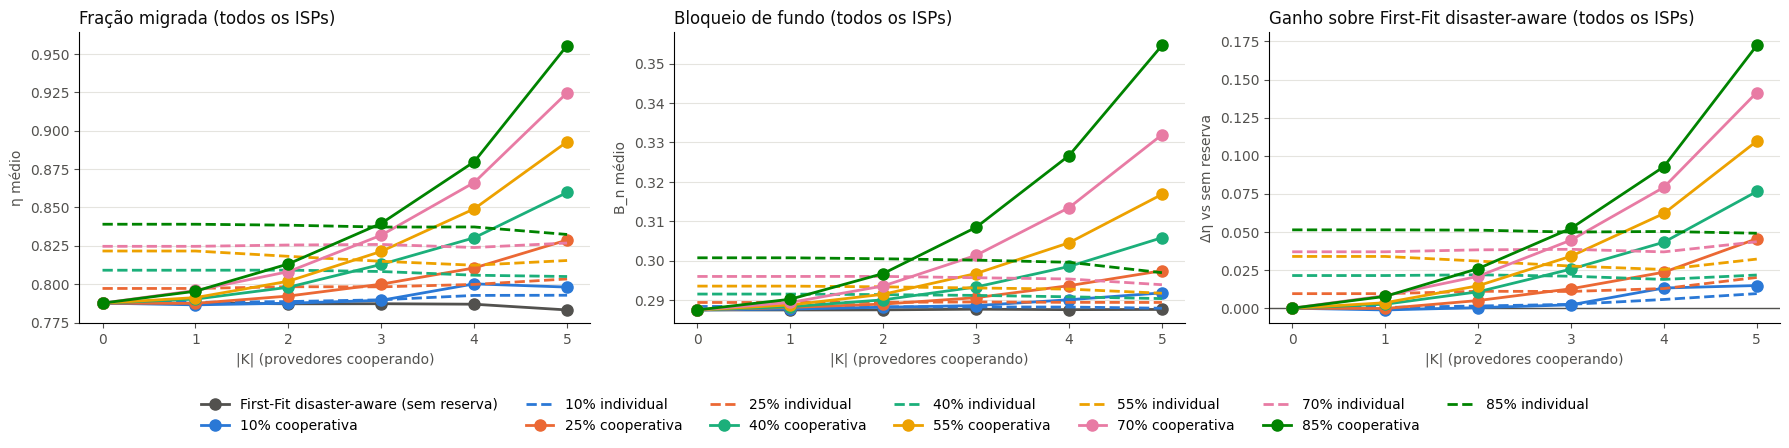

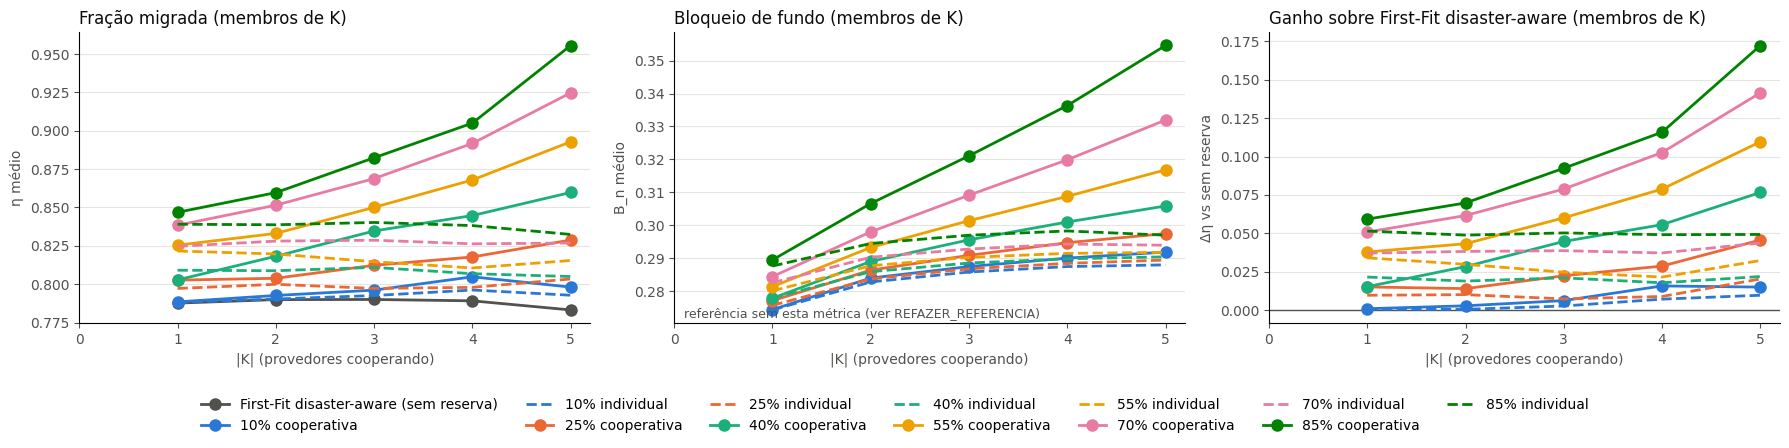

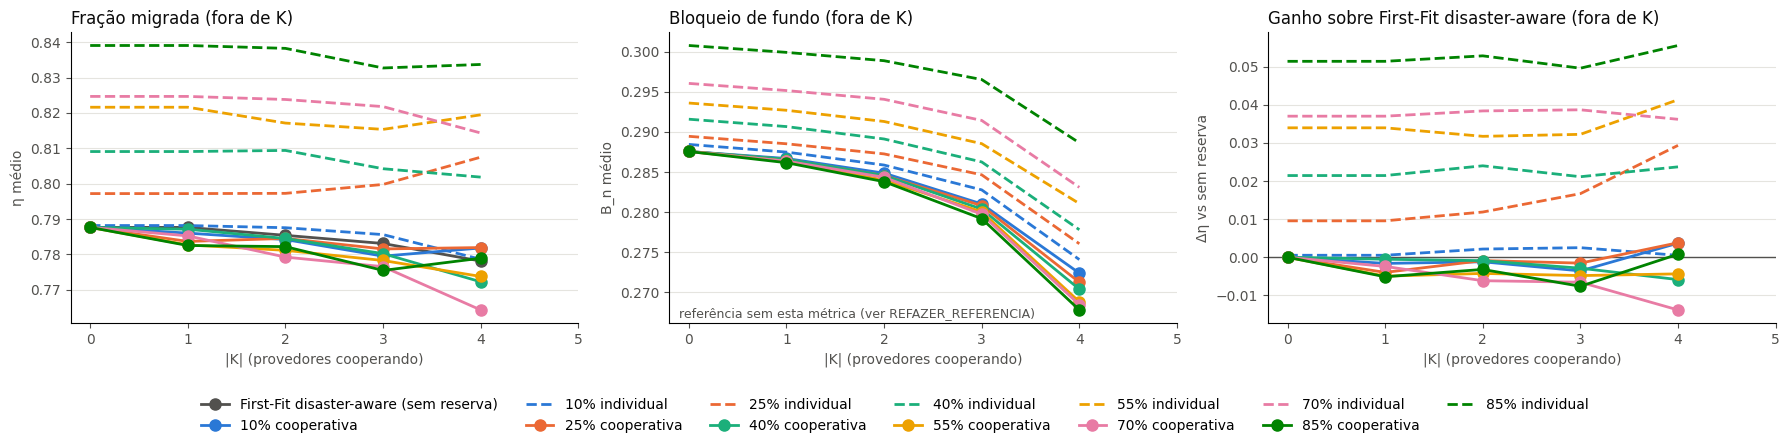

In [18]:
# Fixed palette order, one color per percentage (up to 8)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
CORES = {pct: PALETA[i % len(PALETA)] for i, pct in enumerate(sorted(PORCENTAGENS))}
TEXTO, GRADE, CINZA = "#52514e", "#e5e4df", "#52514e"
ESCOPOS = [("cooperacao", "-", " cooperativa"), ("isolado", "--", " individual")]


def estilo(ax, titulo, ylabel):
    ax.set_title(titulo, loc="left", fontsize=12, color="#0b0b0b")
    ax.set_xlabel("|K| (provedores cooperando)", color=TEXTO)
    ax.set_ylabel(ylabel, color=TEXTO)
    ax.set_xticks(range(I + 1))
    ax.tick_params(colors=TEXTO)
    ax.grid(axis="y", color=GRADE, linewidth=0.8)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)


def figura(col_eta, col_bn, grupo, arquivo, delta_bn=False):
    """Three panels (η, B_n, gain over the no-reserve reference) for one group of ISPs.

    delta_bn=True plots the background blocking as the difference to the reference
    for the same K. Use it for the per-group figures: the ISPs inside/outside K
    change with |K|, so absolute values mix who is in the group with the effect.
    """
    base = resumo[resumo["escopo"] == "pesos"]
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

    paineis = [(axes[0], col_eta, f"Fração migrada ({grupo})", "η médio")]
    if not delta_bn:
        paineis.append((axes[1], col_bn, f"Bloqueio de fundo ({grupo})", "B_n médio"))
    else:
        ax = axes[1]
        ax.axhline(0, color=TEXTO, linewidth=1)
        if col_bn in base and base[col_bn].notna().any():
            ref_bn = base.set_index(["base_index", "K"])[col_bn]
            for pct in PORCENTAGENS:
                for escopo, traco, _ in ESCOPOS:
                    g = resumo[(resumo["pct"] == pct) & (resumo["escopo"] == escopo)].set_index(["base_index", "K"])
                    d = (g[col_bn] - ref_bn).groupby(g["k"]).mean().dropna()
                    ax.plot(d.index, d.values, traco, color=CORES[pct], linewidth=2,
                            marker="o" if escopo == "cooperacao" else None, markersize=8)
        else:
            ax.text(0.02, 0.02, "referência sem esta métrica (ver REFAZER_REFERENCIA)",
                    transform=ax.transAxes, color=TEXTO, fontsize=9)
        estilo(ax, f"Δ bloqueio de fundo vs sem reserva ({grupo})", "ΔB_n (mesmo K)")

    for ax, col, titulo, ylabel in paineis:
        if col in base and base[col].notna().any():
            m = base.groupby("k")[col].mean().dropna()
            ax.plot(m.index, m.values, color=CINZA, linewidth=2, marker="o", markersize=8,
                    label="First-Fit disaster-aware (sem reserva)")
        else:
            ax.text(0.02, 0.02, "referência sem esta métrica (ver REFAZER_REFERENCIA)",
                    transform=ax.transAxes, color=TEXTO, fontsize=9)
        for pct in PORCENTAGENS:
            for escopo, traco, sufixo in ESCOPOS:
                m = resumo[(resumo["pct"] == pct) & (resumo["escopo"] == escopo)].groupby("k")[col].mean().dropna()
                ax.plot(m.index, m.values, traco, color=CORES[pct], linewidth=2,
                        marker="o" if escopo == "cooperacao" else None, markersize=8,
                        label=f"{pct}%{sufixo}")
        estilo(ax, titulo, ylabel)

    # Gain over the reference for the same K and the same group of ISPs
    ax = axes[2]
    ax.axhline(0, color=TEXTO, linewidth=1)
    ref_col = base.set_index(["base_index", "K"])[col_eta]
    for pct in PORCENTAGENS:
        for escopo, traco, _ in ESCOPOS:
            g = resumo[(resumo["pct"] == pct) & (resumo["escopo"] == escopo)].set_index(["base_index", "K"])
            d = (g[col_eta] - ref_col).groupby(g["k"]).mean().dropna()
            ax.plot(d.index, d.values, traco, color=CORES[pct], linewidth=2,
                    marker="o" if escopo == "cooperacao" else None, markersize=8)
    estilo(ax, f"Ganho sobre First-Fit disaster-aware ({grupo})", "Δη vs sem reserva")

    h, l = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.14, 1, 1))  # room for the legend below the x labels
    fig.legend(h, l, frameon=False, loc="lower center", ncol=min(len(l), 7), bbox_to_anchor=(0.5, 0.0))
    fig.savefig(Path("output") / arquivo, dpi=150, bbox_inches="tight")
    plt.show()


# All ISPs
figura("eta_todos", "B_n", "todos os ISPs", "reserva_varredura.png")
# Only the members of K (|K| = 0 has no members)
figura("eta_K", "B_n_K", "membros de K", "reserva_varredura_K.png", delta_bn=True)
# Only the ISPs outside K (|K| = I has none)
figura("eta_isolados", "B_n_isolados", "fora de K", "reserva_varredura_fora_K.png", delta_bn=True)

## Cooperantes $K$ vs não cooperantes $\mathcal{I}\setminus K$

As curvas acima misturam todos os ISPs. Aqui cada grupo aparece separado:

- **Linha de cima:** $\eta(K)$, a média dos cooperantes, e $\eta(\mathcal{I}\setminus K)$, a média dos que não cooperam.
- **Linha de baixo:** a variação de cada grupo em relação ao First-Fit disaster-aware sem reserva, para o **mesmo $K$**. Isso tira o efeito de composição: por exemplo, o ISP 1 migra 100% sempre, então os conjuntos que o contêm têm $\eta(K)$ alto de qualquer forma.

Linha cheia = proteção cooperativa, tracejada = individual, cinza = sem reserva. $\eta(K)$ existe para $|K| \ge 1$; $\eta(\mathcal{I}\setminus K)$ para $|K| \le I-1$.

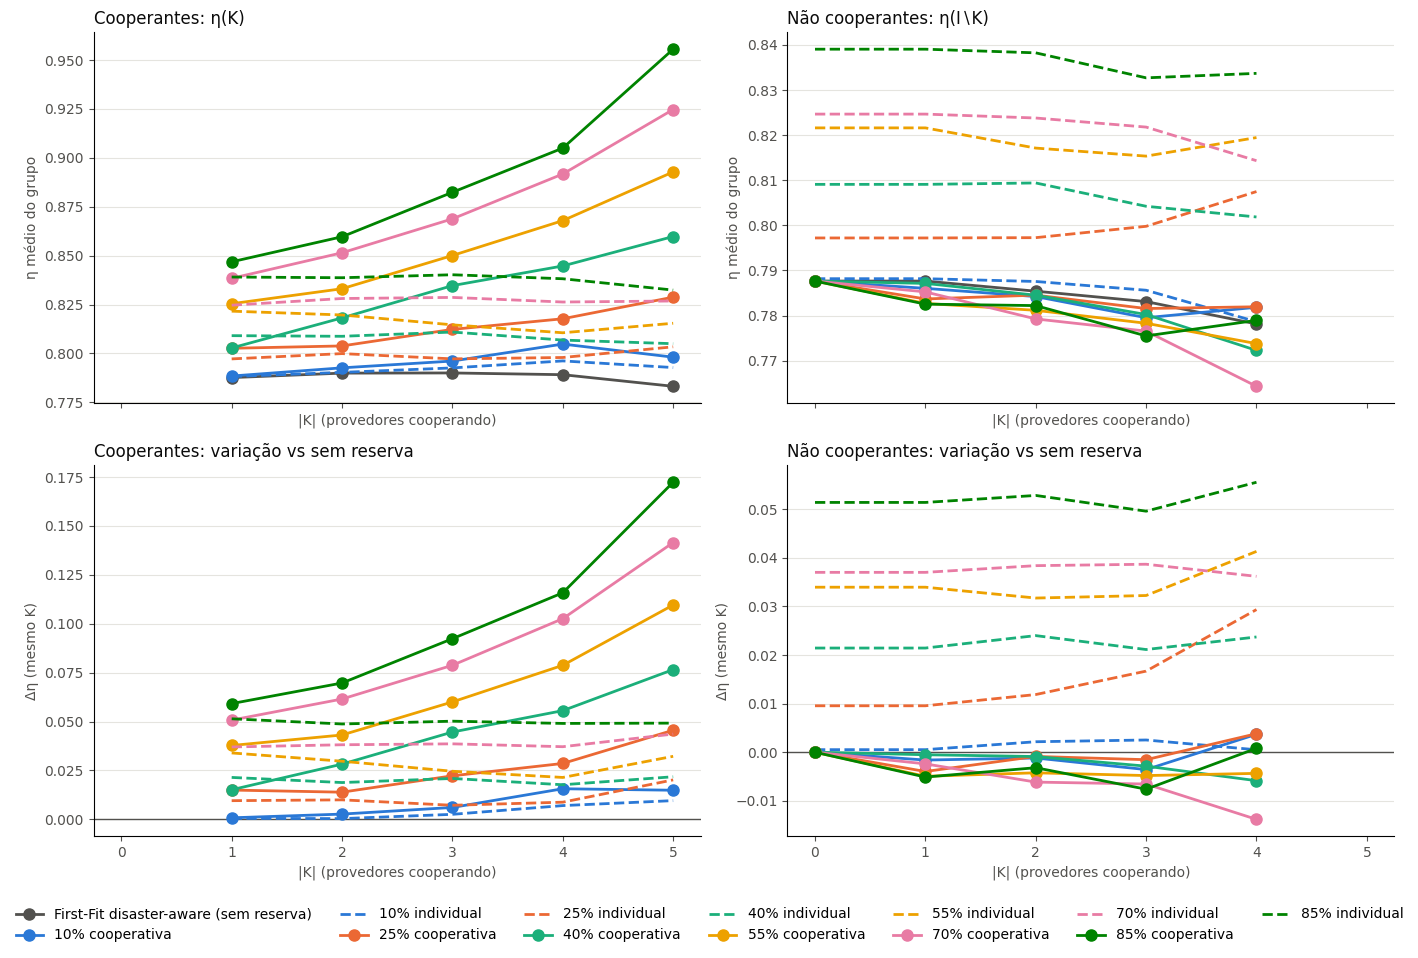

In [19]:
grupos = [("eta_K", "Cooperantes: η(K)"), ("eta_isolados", "Não cooperantes: η(I∖K)")]
ref_grupos = ref[["eta_K", "eta_isolados", "k"]]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for col_idx, (col, titulo) in enumerate(grupos):
    ax_abs, ax_delta = axes[0, col_idx], axes[1, col_idx]
    m = ref_grupos.groupby("k")[col].mean().dropna()
    ax_abs.plot(m.index, m.values, color=CINZA, linewidth=2, marker="o", markersize=8,
                label="First-Fit disaster-aware (sem reserva)")
    ax_delta.axhline(0, color=TEXTO, linewidth=1)
    for pct in PORCENTAGENS:
        for escopo, traco, sufixo in [("cooperacao", "-", " cooperativa"), ("isolado", "--", " individual")]:
            g = resumo[(resumo["pct"] == pct) & (resumo["escopo"] == escopo)].set_index(["base_index", "K"])
            estilo_linha = dict(color=CORES[pct], linewidth=2, markersize=8,
                                marker="o" if escopo == "cooperacao" else None)
            m = g.groupby("k")[col].mean().dropna()
            ax_abs.plot(m.index, m.values, traco, label=f"{pct}%{sufixo}", **estilo_linha)
            d = (g[col] - ref[col]).groupby(g["k"]).mean().dropna()
            ax_delta.plot(d.index, d.values, traco, **estilo_linha)
    estilo(ax_abs, titulo, "η médio do grupo")
    estilo(ax_delta, f"{titulo.split(':')[0]}: variação vs sem reserva", "Δη (mesmo K)")

h, l = axes[0, 0].get_legend_handles_labels()
plt.tight_layout()
fig.legend(h, l, frameon=False, loc="upper center", ncol=min(len(PORCENTAGENS) * 2 + 1, 7), bbox_to_anchor=(0.5, 0.0))
plt.savefig(Path("output") / "reserva_varredura_grupos.png", dpi=150, bbox_inches="tight")
plt.show()

Mesmos números em tabela: variação média de cada grupo vs sem reserva (pontos de η), por $|K|$.

In [20]:
linhas = []
for (pct, escopo), g in resumo[resumo["escopo"] != "pesos"].groupby(["pct", "escopo"]):
    g = g.set_index(["base_index", "K"])
    for col, grupo in [("eta_K", "K"), ("eta_isolados", "I∖K")]:
        d = (g[col] - ref[col]).groupby(g["k"]).mean().dropna()
        for k, v in d.items():
            linhas.append({"grupo": grupo, "escopo": escopo, "pct": pct, "k": k, "d": v})
(pd.DataFrame(linhas)
 .pivot_table(index=["grupo", "escopo", "pct"], columns="k", values="d")
 .round(4))

k                          0       1       2       3       4       5
grupo escopo     pct                                                
I∖K   cooperacao 10   0.0000 -0.0016 -0.0012 -0.0036  0.0037     NaN
                 25   0.0000 -0.0040 -0.0009 -0.0015  0.0038     NaN
                 40   0.0000 -0.0005 -0.0009 -0.0029 -0.0059     NaN
                 55   0.0000 -0.0050 -0.0042 -0.0048 -0.0044     NaN
                 70   0.0000 -0.0024 -0.0062 -0.0065 -0.0138     NaN
                 85   0.0000 -0.0051 -0.0032 -0.0076  0.0008     NaN
      isolado    10   0.0005  0.0005  0.0022  0.0025  0.0005     NaN
                 25   0.0096  0.0096  0.0119  0.0167  0.0294     NaN
                 40   0.0214  0.0214  0.0240  0.0211  0.0237     NaN
                 55   0.0340  0.0340  0.0317  0.0323  0.0413     NaN
                 70   0.0370  0.0370  0.0384  0.0387  0.0362     NaN
                 85   0.0514  0.0514  0.0529  0.0496  0.0556     NaN
K     cooperacao 10      NaN  0.0008  0.0027  0.0061  0.0157  0.0149
                 25      NaN  0.0150  0.0139  0.0223  0.0286  0.0456
                 40      NaN  0.0151  0.0282  0.0447  0.0556  0.0766
                 55      NaN  0.0378  0.0431  0.0600  0.0788  0.1096
                 70      NaN  0.0508  0.0615  0.0788  0.1026  0.1415
                 85      NaN  0.0592  0.0697  0.0924  0.1158  0.1724
      isolado    10      NaN  0.0005  0.0004  0.0026  0.0070  0.0096
                 25      NaN  0.0096  0.0100  0.0072  0.0088  0.0202
                 40      NaN  0.0214  0.0188  0.0209  0.0177  0.0218
                 55      NaN  0.0340  0.0297  0.0246  0.0214  0.0322
                 70      NaN  0.0370  0.0381  0.0386  0.0372  0.0436
                 85      NaN  0.0514  0.0488  0.0502  0.0490  0.0492

## Leitura

- **Melhor porcentagem:** a que tem maior `d_eta` com `d_B_n` aceitável; veja `ganho por ponto de B_n`. Reservar mais protege mais a migração, mas bloqueia mais tráfego de fundo, e acima de certo ponto a migração pode nem conseguir usar toda a reserva.
- **Cooperação vale a pena?** Na tabela "Ganho sobre o First-Fit disaster-aware", compare a linha cooperativa com a individual de cada porcentagem, ambas medidas contra a mesma referência.
- **Isolados:** `d_eta isolados` e `pior d_eta de um isolado` mostram quanto quem não coopera paga.
- Um cenário base só: trate como indicativo.